# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install -q scikit-learn==1.7.2 imbalanced-learn==0.14.0 requests


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        X = self.add_intercept(X)
        if self.w0 is None:
            self.w = np.zeros(X.shape[1])
        else:
            self.w = np.array(self.w0, dtype=float, copy=True)
        self.loss_history.append(self.calc_loss(X, y))
        self.n_iter_ = 0
        self.stop_reason_ = 'max_iter'

        for _ in range(self.max_iter):
            if self.gd_type == 'full':
                grad = self.calc_gradient(X, y)
            elif self.gd_type == 'stochastic':
                batch = rng.integers(len(y), size=self.batch_size)
                grad = self.calc_gradient(X[batch], y[batch])
            else:
                raise ValueError(f'Неизвестный gd_type: {self.gd_type}')

            w_new = self.w - self.eta * grad
            step_norm = np.linalg.norm(w_new - self.w)
            self.w = w_new
            self.n_iter_ += 1
            self.loss_history.append(self.calc_loss(X, y))

            if step_norm < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break

        return self

    def add_intercept(self, X):
        return np.column_stack([np.ones(len(X)), X])

    def sigmoid(self, z):
        # Ограничим z, чтобы exp не переполнялась при больших числах.
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        X = self.add_intercept(np.asarray(X, dtype=float))
        p = self.sigmoid(X @ self.w)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        p = self.sigmoid(X @ self.w)
        return X.T @ (p - y) / len(y)

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        z = X @ self.w
        # logaddexp(0, z) считает log(1 + exp(z)) без переполнения.
        loss_0 = np.logaddexp(0, z)
        loss_1 = np.logaddexp(0, -z)
        return np.mean((1 - y) * loss_0 + y * loss_1)

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 2.49e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

In [6]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)

training_results = {}
for name, model in [('GD', gd), ('SGD', sgd)]:
    training_results[name] = {
        'iterations': model.n_iter_,
        'stop': model.stop_reason_,
    }
pd.DataFrame(training_results).T

,iterations,stop
GD,1000,max_iter
SGD,1000,max_iter


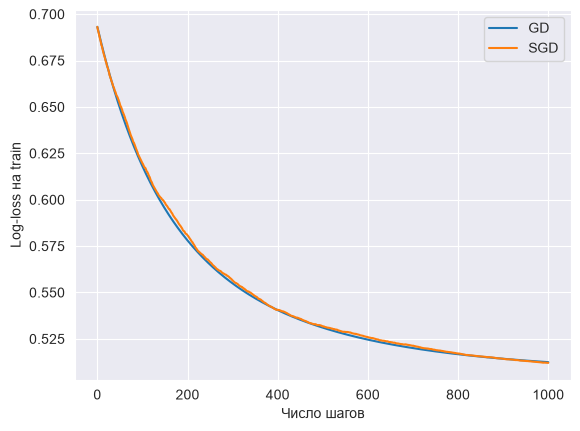

In [7]:
fig, ax = plt.subplots()
ax.plot(gd.loss_history, label='GD')
ax.plot(sgd.loss_history, label='SGD')
ax.set(xlabel='Число шагов', ylabel='Log-loss на train')
ax.legend()
plt.show()

Обе модели остановились по max_iter после 1000 шагов. У GD loss убывает плавно, у SGD тоже убывает, но немного колеблется. Это связано с тем, что каждый раз мы считаем градиент на новом случайном батче. Поэтому даже рядом с минимумом веса могут заметно меняться, и остановиться по tolerance сложнее.

GD на каждом шаге считает градиент по всем 14 000 объектам, SGD по 32. Объекты в батче могут повторяться. При этом для графика обе модели дополнительно считают loss на всём трейне.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

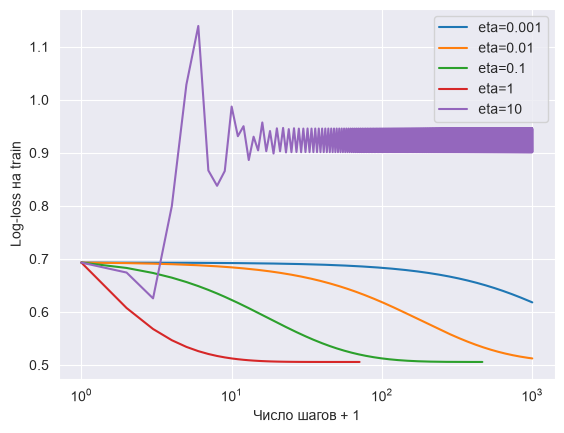

In [8]:
etas = [1e-3, 1e-2, 1e-1, 1, 10]
eta_results = []
fig, ax = plt.subplots()

for eta in etas:
    model = LogReg(eta=eta).fit(X_train, y_train)
    eta_results.append({
        'eta': eta, 'loss': model.loss_history[-1],
        'iterations': model.n_iter_, 'stop': model.stop_reason_,
    })
    ax.plot(np.arange(model.n_iter_ + 1) + 1, model.loss_history, label=f'eta={eta:g}')

ax.set(xscale='log', xlabel='Число шагов + 1', ylabel='Log-loss на train')
ax.legend()
plt.show()

In [9]:
pd.DataFrame(eta_results).set_index('eta').round(4)

,loss,iterations,stop
eta,,,
0.001,0.6181,1000,max_iter
0.010,0.5124,1000,max_iter
0.100,0.5058,465,tolerance
1.000,0.5058,70,tolerance
10.000,0.9013,1000,max_iter


С маленьким шагом спуск идёт медленно. При eta=0.001 за 1000 итераций loss дошёл только до 0.6181, при eta=0.01 до 0.5124. При eta=0.1 и eta=1 получили примерно одинаковый loss 0.5058, но во втором случае хватило 70 шагов вместо 465.

При eta=10 всё заметно хуже. Loss колеблется и в конце равен 0.9013, что даже больше начального значения. Получается, слишком большой шаг заставляет нас перескакивать через минимум.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [10]:
lr = LogisticRegression().fit(X_train, y_train)
lr_no_penalty = LogisticRegression(C=np.inf, tol=1e-9).fit(X_train, y_train)
gd_converged = LogReg(eta=1, tolerance=1e-7, max_iter=5000).fit(X_train, y_train)

results = {}
for name, model in [('GD', gd), ('SGD', sgd), ('sklearn', lr)]:
    results[name] = {
        'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
        'ROC-AUC': metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    }

pd.DataFrame(results).T.round(4)

,accuracy,ROC-AUC
GD,0.7820,0.8388
SGD,0.7825,0.8388
sklearn,0.7765,0.8387


In [11]:
weights = pd.DataFrame({
    'GD': gd.w,
    'sklearn': np.concatenate([lr.intercept_, lr.coef_[0]]),
    'GD (до сходимости)': gd_converged.w,
    'sklearn без штрафа': np.concatenate([lr_no_penalty.intercept_, lr_no_penalty.coef_[0]]),
}, index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])])
weights.round(4)

,GD,sklearn,GD (до сходимости),sklearn без штрафа
intercept,-0.0021,-0.0219,-0.0222,-0.0222
x0,0.0061,0.0027,0.0028,0.0028
x1,0.0070,0.0090,0.0090,0.0090
x2,-0.5472,-0.7227,-0.7232,-0.7232
x3,-0.1445,-0.2623,-0.2628,-0.2628
x4,0.0125,0.0166,0.0165,0.0165
x5,-0.0063,-0.0115,-0.0115,-0.0115
x6,0.0008,0.0056,0.0056,0.0056
x7,0.0391,0.0572,0.0572,0.0572
x8,-0.0024,-0.0012,-0.0012,-0.0012


In [12]:
weight_diff = {
    'По умолчанию': np.linalg.norm(weights['GD'] - weights['sklearn']),
    'Без штрафа, после сходимости': np.linalg.norm(
        weights['GD (до сходимости)'] - weights['sklearn без штрафа']
    ),
}
pd.Series(weight_diff, name='L2 разность весов').round(6)

По умолчанию                    0.356783
Без штрафа, после сходимости    0.000001
Name: L2 разность весов, dtype: float64

Метрики получились близкими. ROC-AUC у всех моделей около 0.839, accuracy у GD и SGD около 0.782, у sklearn около 0.777. Веса при этом различаются. Например, для x2 у нашего GD получили −0.547, у sklearn −0.723.

Причин две. Наш GD с параметрами по умолчанию ещё не сошёлся, а у sklearn по умолчанию есть L2-регуляризация. Если убрать её через C=np.inf и дать GD сойтись, разница между весами по L2-норме получается порядка $10^{-6}$. [Документация sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [13]:
from io import BytesIO

import requests

url = 'https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv'
response = requests.get(url, timeout=30)
response.raise_for_status()
df = pd.read_csv(BytesIO(response.content))

df.shape

(6497, 13)

In [14]:
df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [15]:
wine = df.drop_duplicates()
X = wine.drop(columns='target')
y = wine['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (3724, 12)  Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [16]:
print('Пропусков:', df.isna().sum().sum())

Пропусков: 0


In [17]:
print('Дубликатов:', df.duplicated().sum())

Дубликатов: 1177


In [18]:
pd.Series({
    'train': y_train.mean(),
    'test': y_test.mean(),
}, name='Доля класса 1').round(4)

train    0.1896
test     0.1898
Name: Доля класса 1, dtype: float64

In [19]:
lr_wine = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
const_pred = np.zeros(len(y_test), dtype=int)
lr_pred = lr_wine.predict(X_test)

pd.Series({
    'Константа 0': metrics.accuracy_score(y_test, const_pred),
    'LogisticRegression': metrics.accuracy_score(y_test, lr_pred),
}, name='accuracy').round(4)

Константа 0           0.8102
LogisticRegression    0.8152
Name: accuracy, dtype: float64

Пропусков нет, полных дубликатов 1177. Удаляем их до разбиения, чтобы одинаковые строки не попали и в трейн, и в тест. По самим данным мы не можем проверить, были ли это разные образцы вина с одинаковыми признаками, поэтому здесь считаем полные повторы дубликатами.

stratify=y сохраняет примерно одинаковую долю хороших вин в обеих выборках. Получилось 18.96% на трейне и 18.98% на тесте.

У константы accuracy 81.02%, у логистической регрессии 81.52%. Разница совсем небольшая. Получается, можно вообще не находить хорошие вина и всё равно иметь accuracy выше 80%, так что для нашей задачи одной этой метрики мало.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

In [20]:
tp = np.sum((y_test == 1) & (lr_pred == 1))
tn = np.sum((y_test == 0) & (lr_pred == 0))
fp = np.sum((y_test == 0) & (lr_pred == 1))
fn = np.sum((y_test == 1) & (lr_pred == 0))
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

TP=92, TN=1209, FP=84, FN=211


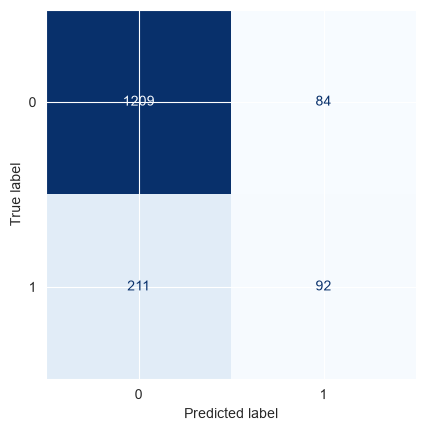

In [21]:
confusion = np.array([[tn, fp], [fn, tp]])
assert np.array_equal(confusion, metrics.confusion_matrix(y_test, lr_pred))

metrics.ConfusionMatrixDisplay(confusion).plot(cmap='Blues', colorbar=False)
plt.show()

FP означает, что мы добавили в подборку посредственное вино. FN означает, что пропустили хорошее. Чаще встречается вторая ошибка, 211 случаев против 84.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [22]:
def fbeta(precision, recall, beta=1):
    denominator = beta**2 * precision + recall
    if denominator == 0:
        return 0.0
    return (1 + beta**2) * precision * recall / denominator


precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0

scores = {
    'precision': [precision, metrics.precision_score(y_test, lr_pred, zero_division=0)],
    'recall': [recall, metrics.recall_score(y_test, lr_pred, zero_division=0)],
}
for beta in [1, 0.5, 2]:
    scores[f'F{beta:g}'] = [
        fbeta(precision, recall, beta),
        metrics.fbeta_score(y_test, lr_pred, beta=beta, zero_division=0),
    ]

scores = pd.DataFrame(scores, index=['Вручную', 'sklearn']).T
assert np.allclose(scores['Вручную'], scores['sklearn'])
scores.round(4)

,Вручную,sklearn
precision,0.5227,0.5227
recall,0.3036,0.3036
F1,0.3841,0.3841
F0.5,0.4568,0.4568
F2,0.3314,0.3314


В F0.5 больший вес имеет precision, в F2 — recall. В F1 они учитываются одинаково. Если клиенты сильно расстраиваются из-за посредственных вин, я бы выбрал F0.5. Если мы обещаем самую широкую подборку хороших вин, то F2, потому что в таком случае важнее пропустить как можно меньше хороших вин.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

In [23]:
gd_wine = make_pipeline(
    StandardScaler(), LogReg(eta=1, max_iter=15000, tolerance=1e-7)
).fit(X_train, y_train)
gd_logreg = gd_wine.named_steps['logreg']
print('GD:', gd_logreg.n_iter_, 'шагов,', gd_logreg.stop_reason_)

GD: 4876 шагов, tolerance


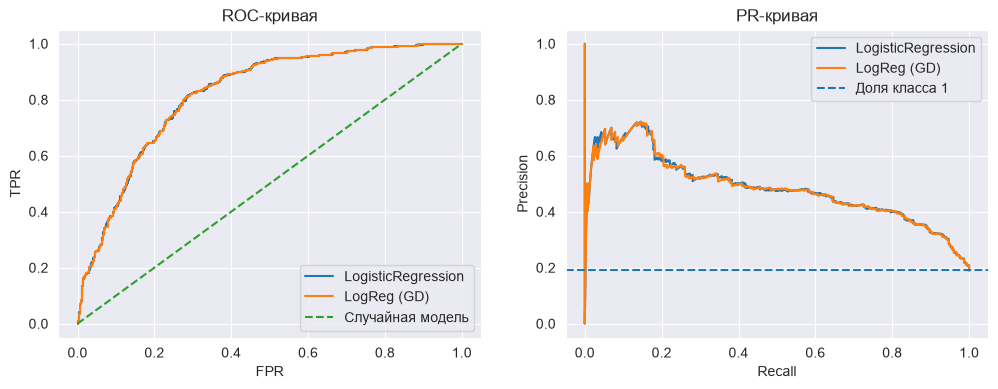

In [24]:
wine_models = {'LogisticRegression': lr_wine, 'LogReg (GD)': gd_wine}
curve_scores = {}
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4))

for name, model in wine_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = metrics.roc_curve(y_test, proba)
    pr_precision, pr_recall, _ = metrics.precision_recall_curve(y_test, proba)
    ax_roc.plot(fpr, tpr, label=name)
    ax_pr.plot(pr_recall, pr_precision, label=name)
    curve_scores[name] = {
        'ROC-AUC': metrics.roc_auc_score(y_test, proba),
        'PR-AUC (AP)': metrics.average_precision_score(y_test, proba),
    }

ax_roc.plot([0, 1], [0, 1], '--', label='Случайная модель')
ax_roc.set(xlabel='FPR', ylabel='TPR', title='ROC-кривая')
ax_roc.legend()
ax_pr.axhline(y_test.mean(), linestyle='--', label='Доля класса 1')
ax_pr.set(xlabel='Recall', ylabel='Precision', title='PR-кривая')
ax_pr.legend()
plt.show()

In [25]:
pd.DataFrame(curve_scores).T.round(5)

,ROC-AUC,PR-AUC (AP)
LogisticRegression,0.82088,0.48477
LogReg (GD),0.82056,0.48377


In [26]:
p = lr_wine.predict_proba(X_test)[:, 1]
p_safe = np.clip(p, 1e-15, 1 - 1e-15)
transformed = {
    'p': p, '10 * p': 10 * p, 'p ** 3': p**3,
    'logit(p)': np.log(p_safe / (1 - p_safe)), '-p': -p,
    'Метки 0/1': lr_pred,
}
auc_scores = {}
for name, values in transformed.items():
    auc_scores[name] = metrics.roc_auc_score(y_test, values)

pd.Series(auc_scores, name='ROC-AUC').round(5)

p            0.82088
10 * p       0.82088
p ** 3       0.82088
logit(p)     0.82088
-p           0.17912
Метки 0/1    0.61933
Name: ROC-AUC, dtype: float64

У sklearn обе метрики немного выше. ROC-AUC 0.82088 против 0.82056, AP 0.48477 против 0.48377. По сути модели показывают очень близкие результаты.

Для случайной модели ориентир по AP около 0.19. Если выбирать вина случайно, доля хороших среди выбранных будет примерно такой же, как во всём тесте. Поэтому здесь берём долю класса 1, которая заметно меньше 0.5.

Умножение на 10, куб и logit сохраняют порядок вероятностей. Поэтому ROC-AUC во всех трёх случаях остался 0.82088. После смены знака порядок обратный и получаем 1 − 0.82088 = 0.17912.

Если передать метки 0/1, мы потеряем информацию о том, насколько модель уверена в каждом предсказании. На ROC останется одна точка между концами кривой. Тогда ROC-AUC равен (TPR + TNR) / 2, здесь получилось 0.61933.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

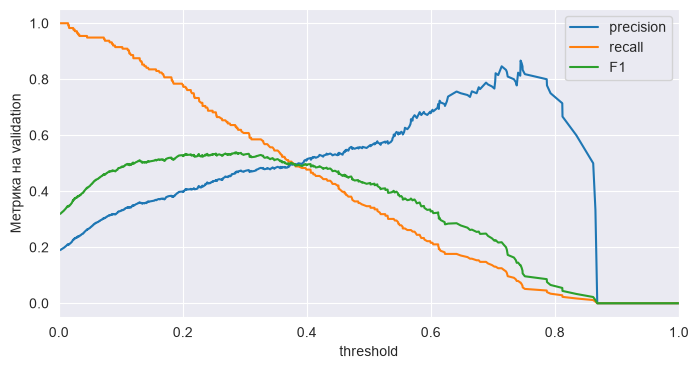

In [27]:
def threshold_metrics(y_true, proba, threshold):
    pred = proba >= threshold
    precision = metrics.precision_score(y_true, pred, zero_division=0)
    recall = metrics.recall_score(y_true, pred, zero_division=0)
    return {'precision': precision, 'recall': recall, 'F1': fbeta(precision, recall)}


X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
lr_val = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_fit, y_fit)
val_proba = lr_val.predict_proba(X_val)[:, 1]

# Предсказания меняются только при переходе через одну из вероятностей.
thresholds = np.unique(np.concatenate([[0], val_proba, [1]]))
val_scores = []
for t in thresholds:
    res = threshold_metrics(y_val, val_proba, t)
    res['threshold'] = t
    val_scores.append(res)

val_scores = pd.DataFrame(val_scores).set_index('threshold')
ax = val_scores.plot(figsize=(8, 4), ylabel='Метрика на validation')
ax.set_xlim(0, 1)
plt.show()

In [28]:
t_f1 = val_scores['F1'].idxmax()
valid_thresholds = val_scores[val_scores['recall'] >= 0.7]
t_recall = valid_thresholds['precision'].idxmax()
chosen_thresholds = {'0.5': 0.5, 't_F1': t_f1, 't_R': t_recall}

val_scores.loc[[t_f1, t_recall]].round(4)

,precision,recall,F1
threshold,,,
0.286550,0.4703,0.6307,0.5388
0.236359,0.4261,0.7045,0.5310


In [29]:
# lr_wine из 2.1 уже обучена на всём train с теми же параметрами.
test_proba = lr_wine.predict_proba(X_test)[:, 1]
threshold_results = {}
for name, t in chosen_thresholds.items():
    res = {'threshold': t}
    res.update(threshold_metrics(y_test, test_proba, t))
    threshold_results[name] = res

pd.DataFrame(threshold_results).T.round(4)

,threshold,precision,recall,F1
0.5,0.5000,0.5227,0.3036,0.3841
t_F1,0.2865,0.4574,0.6205,0.5266
t_R,0.2364,0.4213,0.7063,0.5277


На валидации получили t_F1 около 0.287 и t_R около 0.236. Для t_R recall на валидации 70.45%, на тесте 70.63%, то есть условие выполнилось. На другой выборке результат может быть другим. Состав вин меняется, да и после обучения на всём трейне вероятности немного меняются.

Я бы выбрал t_R, если сервису нужно находить хотя бы 70% хороших вин. При нём precision 42.13%. У t_F1 precision выше, 45.74%, но recall только 62.05%. При пороге 0.5 мы вообще пропускаем почти 70% хороших вин.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [30]:
def model_metrics(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    res = {}
    res['accuracy'] = metrics.accuracy_score(y, proba >= threshold)
    res.update(threshold_metrics(y, proba, threshold))
    res['ROC-AUC'] = metrics.roc_auc_score(y, proba)
    res['PR-AUC (AP)'] = metrics.average_precision_score(y, proba)
    return res


lr_balanced = make_pipeline(
    StandardScaler(), LogisticRegression(class_weight='balanced')
).fit(X_train, y_train)
test_metrics = {}
for name, model in wine_models.items():
    test_metrics[name] = model_metrics(model, X_test, y_test)
test_metrics['class_weight=balanced'] = model_metrics(lr_balanced, X_test, y_test)

train_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (len(train_counts) * train_counts)
class_weights.rename('Вес класса').round(4)

target
0    0.6170
1    2.6374
Name: Вес класса, dtype: float64

In [31]:
pd.DataFrame(test_metrics).T.loc[['LogisticRegression', 'class_weight=balanced']].round(4)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
LogisticRegression,0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
class_weight=balanced,0.7343,0.3987,0.7855,0.5289,0.8209,0.4811


Вес класса считаем как N / (2 * N_k), где N — размер трейна, N_k — число объектов нужного класса. Для класса 0 получили 0.617, для класса 1 получили 2.637. Получается, ошибка на хорошем вине теперь сильнее влияет на обучение. [Документация sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html)

Recall вырос с 30.4% до 78.5%, precision снизился с 52.3% до 39.9%. F1 вырос с 0.384 до 0.529, accuracy снизилась с 81.5% до 73.4%. Модель стала рекомендовать больше вин, поэтому нашла больше хороших, но добавила и больше посредственных. ROC-AUC и AP почти не изменились, потому что порядок вин по предсказанным вероятностям остался похожим.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [32]:
from imblearn.pipeline import make_pipeline as make_resampling_pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import NearMiss, RandomUnderSampler

samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE),
}

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)

resampled_counts = {}
for name, sampler in samplers.items():
    # Отдельно посмотрим, сколько объектов каждого класса получилось.
    _, y_resampled = sampler.fit_resample(X_train_scaled, y_train)
    counts = y_resampled.value_counts().sort_index()
    resampled_counts[name] = counts

    model = make_resampling_pipeline(StandardScaler(), sampler, LogisticRegression())
    model.fit(X_train, y_train)
    test_metrics[name] = model_metrics(model, X_test, y_test)

smote_first = make_resampling_pipeline(
    SMOTE(random_state=RANDOM_STATE), StandardScaler(), LogisticRegression()
).fit(X_train, y_train)
test_metrics['SMOTE до масштабирования'] = model_metrics(smote_first, X_test, y_test)

pd.DataFrame(resampled_counts).T.rename(columns={0: 'Класс 0', 1: 'Класс 1'})

target,Класс 0,Класс 1
RandomUnderSampler,706,706
NearMiss,706,706
RandomOverSampler,3018,3018
SMOTE,3018,3018


In [33]:
pd.DataFrame(test_metrics).T.drop(index='LogReg (GD)').round(4)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
LogisticRegression,0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
class_weight=balanced,0.7343,0.3987,0.7855,0.5289,0.8209,0.4811
RandomUnderSampler,0.7331,0.3959,0.7723,0.5235,0.8206,0.4799
NearMiss,0.6466,0.3294,0.8317,0.4719,0.7865,0.4479
RandomOverSampler,0.7331,0.3980,0.7921,0.5298,0.8211,0.4811
SMOTE,0.7350,0.3976,0.7690,0.5242,0.8196,0.4796
SMOTE до масштабирования,0.7393,0.4024,0.7690,0.5283,0.8216,0.4852


Нужен пайплайн из imblearn, потому что у методов балансировки есть fit_resample, который меняет и X, и y. Обычный пайплайн sklearn ожидает шаги с transform. При predict ресемплинг пропускается, поэтому тест остаётся в исходном виде.

Если балансировать до разбиения, копия одного объекта может попасть и в трейн, и в тест. При SMOTE похожая проблема возникает с искусственно созданными объектами. Кроме того, доля хороших вин в тесте станет другой, и мы будем оценивать модель на другом распределении данных.

Из четырёх методов с масштабированием в начале лучший AP у RandomOverSampler (0.4811), худший у NearMiss (0.4479). RandomOverSampler сохраняет все исходные строки, а NearMiss удаляет большую часть класса 0. Возможно, из-за этого модель теряет полезную информацию.

Для NearMiss и SMOTE порядок шагов важен, потому что оба метода используют расстояния между объектами. После масштабирования ближайшие соседи могут измениться. У RandomUnderSampler и RandomOverSampler выбор строк при том же seed будет одинаковым. Но если обучать scaler после балансировки, средние и дисперсии признаков будут другими. Это может повлиять на результат модели с регуляризацией.

В нашем эксперименте SMOTE до масштабирования дал AP 0.4852 вместо 0.4796. Recall в обоих случаях около 76.9%.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

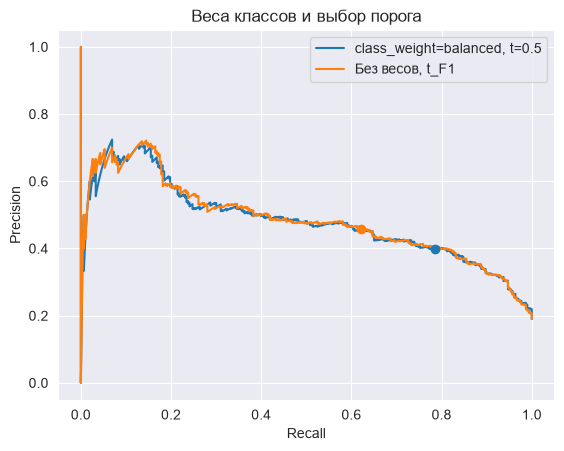

In [34]:
comparisons = {
    'class_weight=balanced, t=0.5': (lr_balanced, 0.5),
    'Без весов, t_F1': (lr_wine, t_f1),
}
fig, ax = plt.subplots()
comparison_scores = {}
for name, (model, threshold) in comparisons.items():
    proba = model.predict_proba(X_test)[:, 1]
    pr_precision, pr_recall, _ = metrics.precision_recall_curve(y_test, proba)
    point = threshold_metrics(y_test, proba, threshold)
    comparison_scores[name] = point
    line = ax.plot(pr_recall, pr_precision, label=name)[0]
    ax.scatter(point['recall'], point['precision'], color=line.get_color(), zorder=3)

ax.set(xlabel='Recall', ylabel='Precision', title='Веса классов и выбор порога')
ax.legend()
plt.show()

In [35]:
pd.DataFrame(comparison_scores).T.round(4)

,precision,recall,F1
"class_weight=balanced, t=0.5",0.3987,0.7855,0.5289
"Без весов, t_F1",0.4574,0.6205,0.5266


Кривые почти совпадают. AP у модели с весами 0.4811, у обычной модели 0.4848. Но выбранные точки на них заметно отличаются. С весами получили recall 78.5% и precision 39.9%, с t_F1 получили recall 62.0% и precision 45.7%. F1 при этом у обеих моделей около 0.53.

Получается, здесь добавление весов в основном даёт эффект, похожий на снижение порога. Полностью одинаковыми эти подходы назвать нельзя. Веса классов меняют само обучение и могут поменять порядок вин по вероятностям, а при смене порога мы просто выбираем другую точку на той же кривой.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [36]:
summary = test_metrics.copy()
res = {}
res['accuracy'] = metrics.accuracy_score(y_test, const_pred)
res.update(threshold_metrics(y_test, const_pred, 0.5))
res['ROC-AUC'] = metrics.roc_auc_score(y_test, const_pred)
res['PR-AUC (AP)'] = metrics.average_precision_score(y_test, const_pred)
summary['Константа 0'] = res
summary['LogisticRegression, t_F1'] = model_metrics(lr_wine, X_test, y_test, t_f1)
summary['LogisticRegression, t_R'] = model_metrics(lr_wine, X_test, y_test, t_recall)
pd.DataFrame(summary).T.round(4)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
LogisticRegression,0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
LogReg (GD),0.8145,0.5200,0.3003,0.3808,0.8206,0.4838
class_weight=balanced,0.7343,0.3987,0.7855,0.5289,0.8209,0.4811
RandomUnderSampler,0.7331,0.3959,0.7723,0.5235,0.8206,0.4799
NearMiss,0.6466,0.3294,0.8317,0.4719,0.7865,0.4479
RandomOverSampler,0.7331,0.3980,0.7921,0.5298,0.8211,0.4811
SMOTE,0.7350,0.3976,0.7690,0.5242,0.8196,0.4796
SMOTE до масштабирования,0.7393,0.4024,0.7690,0.5283,0.8216,0.4852
Константа 0,0.8102,0.0000,0.0000,0.0000,0.5000,0.1898
"LogisticRegression, t_F1",0.7882,0.4574,0.6205,0.5266,0.8209,0.4848


Для приложения беру обычную логистическую регрессию со StandardScaler и порогом t_R около 0.236. Порог выбрали на валидации, чтобы находить хотя бы 70% хороших вин. На тесте получили recall 70.63% и precision 42.13%.

У модели с весами recall выше, 78.55%, но precision ниже, 39.87%. Для нашего сервиса я бы выбрал первый вариант. Нужную долю хороших вин на этом тесте находим, при этом доля посредственных в подборке меньше.

У SMOTE до масштабирования AP выше примерно на 0.0004. Разница небольшая, и выбирать другую модель только из-за результата на тесте было бы неправильно.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [37]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = lr_wine
final_threshold = t_recall

joblib.dump(final_model, app_dir / 'model.joblib')
config = {'threshold': float(final_threshold)}
with open(app_dir / 'config.json', 'w', encoding='utf-8') as file:
    json.dump(config, file)
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

[Архив с приложением и инструкцией](wine_app.zip)

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷